# Complex analysis 5: Taylor and Laurent series

*Learning path: complex analysis, part 5 of 8.* [Index](README.md) · Previous: [Cauchy's theorem](04-cauchy.ipynb) · Next: [Residues](06-residues.ipynb)

The function $1/(1 + x^2)$ is smooth on the whole real line, with no trouble anywhere. Yet its Taylor series at 0,
$1 - x^2 + x^4 - \cdots$, stops converging at $|x| = 1$. Why there? Nothing happens to the function at $x = 1$. The
answer is in the complex plane: $1/(1 + z^2)$ blows up at $z = \pm i$, at distance 1 from the origin, and a power series
converges exactly on the largest disc that avoids the singularities. This lesson explains that, then extends power
series to **Laurent series** with negative powers, which describe functions near their singularities and sort the
singularities into three kinds.

**Who this is for.** You have done [lesson 4](04-cauchy.ipynb) and know Taylor polynomials
([foundations](../foundations/README.md)).

**What you will be able to do afterwards:**

1. predict the radius of convergence of a Taylor series from the singularities of the function;
2. compute Laurent series with `laurent`, on different annuli of the same function;
3. classify an isolated singularity as removable, a pole of some order, or essential;
4. read the residue off a Laurent series, the number that lesson 6 turns into integrals.

Plan about an hour.

## 1. The radius of convergence

The Taylor polynomials of $1/(1 + x^2)$ at 0 follow the function closely inside $(-1, 1)$ and fly off outside, however
many terms you take:

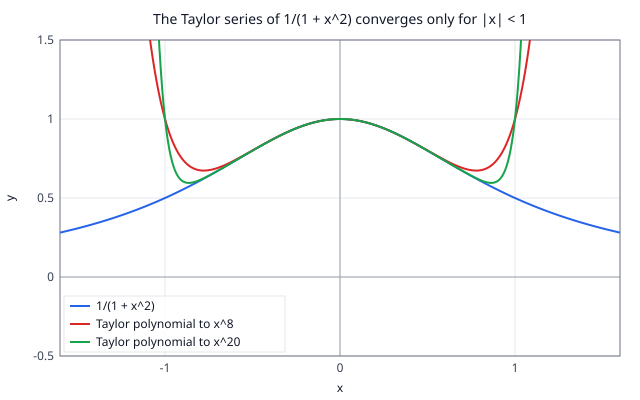

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
p = plot(1/(1 + x^2), x, -1.6, 1.6);
p = show(p, plot(taylor(1/(1 + x^2), x, 0, 8), x, -1.6, 1.6));
p = show(p, plot(taylor(1/(1 + x^2), x, 0, 20), x, -1.6, 1.6));
p = window(p, -1.6, 1.6, -0.5, 1.5);
p = legend(p, "1/(1 + x^2)", "Taylor polynomial to x^8", "Taylor polynomial to x^20");
labels(title(p, "The Taylor series of 1/(1 + x^2) converges only for |x| < 1"), "x", "y")

Cauchy's integral formula explains this. Around a circle $|z - a| = r$ on which $f$ is analytic, expand
$\frac{1}{z - w} = \frac{1}{z - a}\sum_n \left(\frac{w - a}{z - a}\right)^n$ inside the formula of lesson 4: $f$ equals
its Taylor series at every $w$ with $|w - a| < r$. So **the Taylor series of $f$ at $a$ converges on the largest disc
around $a$ on which $f$ is analytic**, and its radius is the distance from $a$ to the nearest singularity. For
$1/(1 + z^2)$ the singularities are $\pm i$, so the radius at 0 is 1:

In [2]:
poles(1/(1 + z^2), z)

[-i, 1,  i/2;
  i, 1, -i/2]

> Poles: one row [pole, order, residue] for each zero of the denominator that the numerator does not cancel.

(The rows are pole, order and residue.) The same function expanded at $a = 1$ has radius $|1 - i| = \sqrt 2$. Real
calculus can't see this: it is the complex poles that limit the real series.

**Try this.** What is the radius of convergence of the Taylor series of $\tan z$ at 0? Of $1/(z^2 - 4z + 5)$ at 0?
Check the second with `poles`.

## 2. Laurent series

Near a singularity a power series is not enough, but a series with negative powers is. If $f$ is analytic on an
**annulus** $r < |z - a| < R$, then

$$f(z) = \sum_{n=-\infty}^{\infty} c_n (z - a)^n, \qquad c_n = \frac{1}{2\pi i}\oint \frac{f(z)}{(z - a)^{n+1}}\,dz,$$

the **Laurent series**. `laurent(f, z, a, n)` computes it up to $(z - a)^n$. For $f = 1/(z(z - 1))$, around 0 and
around 1:

In [3]:
laurent(1/(z*(z - 1)), z, 0, 3)
laurent(1/(z*(z - 1)), z, 1, 3)

-1/z-1-z-z^2-z^3

> Laurent series around z = 0: z = 0 is a pole of order 1: the principal part has powers down to z^−1. The residue (the coefficient of z^−1) is -1.

1/(z-1)-1+(z-1)-(z-1)^2+(z-1)^3

> Laurent series around z = 1: z = 1 is a pole of order 1: the principal part has powers down to (z − 1)^−1. The residue (the coefficient of (z − 1)^−1) is 1.

The first is valid on $0 < |z| < 1$; it is $-1/z$ times the geometric series $1/(1 - z)$. But the same function has a
**different** Laurent series on $|z| > 1$, outside both singularities. To find it, put $z = 1/w$, so that large $z$ is
small $w$, and expand in $w$:

In [4]:
laurent(subs(1/(z*(z - 1)), z, 1/w), w, 0, 4)

w^2+w^3+w^4

> Laurent series around w = 0: f is analytic at w = 0, so this is its Taylor series. The residue (the coefficient of w^−1) is 0.

So on $|z| > 1$, $f = 1/z^2 + 1/z^3 + 1/z^4 + \cdots$: no positive powers at all. One function, three annuli
($0 < |z| < 1$, $0 < |z - 1| < 1$, $|z| > 1$), three different series. A Laurent series belongs to a function **and** an
annulus.

**Try this.** Check the series on $|z| > 1$ by hand: $\frac{1}{z(z - 1)} = \frac{1}{z^2}\cdot\frac{1}{1 - 1/z}$.

## 3. Three kinds of singularity

An isolated singularity at $a$ is classified by the negative powers of its Laurent series on $0 < |z - a| < r$, the
**principal part**:

* **removable:** no negative powers. The function only looks singular; defining $f(a) = c_0$ makes it analytic.
* **pole of order $m$:** finitely many, down to $(z - a)^{-m}$. Then $|f| \to \infty$ like $|z - a|^{-m}$.
* **essential:** infinitely many negative powers.

`laurent` says which in its notes:

In [5]:
laurent(sin(z)/z, z, 0, 4)
laurent(cos(z)/z^3, z, 0, 2)
laurent(1/sin(z), z, 0, 3)
laurent(exp(1/z), z, 0, 0)

1-z^2/6+z^4/120

> Laurent series around z = 0: f is analytic at z = 0, so this is its Taylor series. The residue (the coefficient of z^−1) is 0.

1/z^3-1/(2*z)+z/24

> Laurent series around z = 0: z = 0 is a pole of order 3: the principal part has powers down to z^−3. The residue (the coefficient of z^−1) is -1/2.

1/z+z/6+7*z^3/360

> Laurent series around z = 0: z = 0 is a pole of order 1: the principal part has powers down to z^−1. The residue (the coefficient of z^−1) is 1.

1/(720*z^6)+1/(120*z^5)+1/(24*z^4)+1/(6*z^3)+1/(2*z^2)+1/z+1

> Laurent series around z = 0: z = 0 is an essential singularity: infinitely many negative powers, shown down to z^−6. The residue (the coefficient of z^−1) is 1.

$\sin z/z$ is removable (its value at 0 is 1), $\cos z/z^3$ has a pole of order 3, $1/\sin z$ a simple pole, and
$e^{1/z}$ an essential singularity. Near a pole the domain coloring is orderly: the colors turn $m$ times around a white
point. Near an essential singularity it is wild:

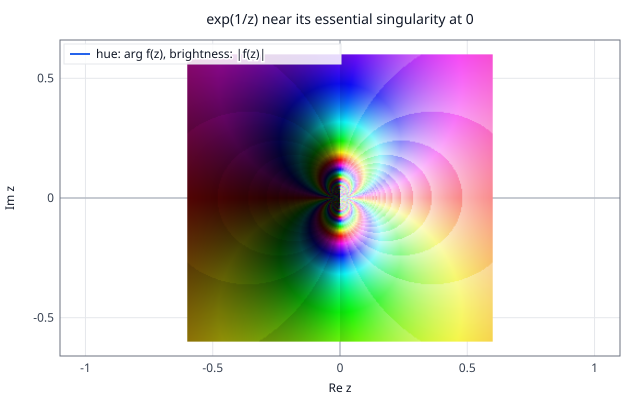

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
p = cplot(exp(1/z), z, -0.6, 0.6, -0.6, 0.6);
labels(title(p, "exp(1/z) near its essential singularity at 0"), "Re z", "Im z")

Every color appears, at every brightness, in every small disc around 0. This is the **Casorati–Weierstrass theorem**:
near an essential singularity $f$ comes arbitrarily close to every complex value. (Picard's great theorem says more:
it takes every value, with at most one exception, infinitely often; $e^{1/z}$ misses only 0.)

**Try this.** Classify the singularity at 0 of $(1 - \cos z)/z^2$, of $1/(z^2\sin z)$ and of $\sin(1/z)$.

## 4. The residue

The coefficient $c_{-1}$ of the Laurent series is special. Integrate the series term by term around a circle in the
annulus: by lesson 3, $\oint (z - a)^n\,dz = 0$ for every $n$ except $n = -1$, which gives $2\pi i$. So

$$\oint f\,dz = 2\pi i\,c_{-1}.$$

That coefficient is called the **residue** of $f$ at $a$: what is left of the series after integrating. `laurent`
reports it, and `residue` computes it directly. For $z^2 e^{1/z}$:

In [7]:
laurent(z^2*exp(1/z), z, 0, 1)
residue(z^2*exp(1/z), z, 0)
cint(z^2*exp(1/z), z, exp(i*t), t, 0, 2*pi)
eval(2*pi*i/6)

1/(40320*z^6)+1/(5040*z^5)+1/(720*z^4)+1/(120*z^3)+1/(24*z^2)+1/(6*z)+1/2+z

> Laurent series around z = 0: z = 0 is an essential singularity: infinitely many negative powers, shown down to z^−6. The residue (the coefficient of z^−1) is 1/6.

1/6

> Residue of f at z = 0: an essential singularity: the residue is the coefficient of 1/(z − a) in the Laurent series.

1.0471975512*i

> Contour integral of f dz along z = exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

1.0471975511965976*i

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The integral around the essential singularity is $2\pi i/6$, read off one coefficient of an infinite series.
[Lesson 6](06-residues.ipynb) turns this into the residue theorem.

**Try this.** Find the residue of $e^z/z^4$ at 0 from its Laurent series, and check it against `cint` around the unit
circle.

## Summary

* The Taylor series of $f$ at $a$ converges on the largest disc around $a$ where $f$ is analytic: the radius is the
  distance to the nearest singularity, which may be complex even for a real function.
* On an annulus $r < |z - a| < R$, $f = \sum_{n=-\infty}^\infty c_n(z - a)^n$; different annuli give different series.
  `laurent(f, z, a, n)` computes it; $z = 1/w$ gives the series for large $|z|$.
* Singularities: removable (no negative powers), pole of order $m$ (down to $(z - a)^{-m}$), essential (infinitely many);
  near an essential singularity $f$ comes close to every value.
* The residue $c_{-1}$ gives the integral: $\oint f\,dz = 2\pi i\,c_{-1}$.

Next: [residues](06-residues.ipynb).

## Exercises

1. **Radius.** Find the radius of convergence of the Taylor series of $1/(e^z - 1) - 1/z$ at 0. (Hint: where is
   $e^z = 1$?)
2. **Annuli.** Find the Laurent series of $1/((z - 1)(z - 2))$ on $1 < |z| < 2$. (Hint: partial fractions; expand
   $1/(z - 1)$ in powers of $1/z$ and $1/(z - 2)$ in powers of $z$.)
3. **Order of a pole.** What is the order of the pole of $1/(1 - \cos z)$ at 0? Check with `laurent`.
4. **Essential.** Show that $\sin(1/z)$ has an essential singularity at 0 and residue 1 there.
5. **Removable.** For which value of $c$ is $f(z) = (e^z - 1 - cz)/z^2$ analytic at 0 after removing the singularity,
   with no $1/z$ term? (Hint: look at $c_{-1}$.)

## Hints and answers

* **Section 1, Try this.** $\tan z$ has poles at $\pm\pi/2$, so the radius is $\pi/2$. $z^2 - 4z + 5 = 0$ at $2 \pm i$,
  at distance $\sqrt 5$ from 0.
* **Section 2, Try this.** $\frac{1}{z^2}(1 + 1/z + 1/z^2 + \cdots)$ for $|1/z| < 1$.
* **Section 3, Try this.** Removable (the series starts $\tfrac12 - z^2/24$); a pole of order 3; essential.
* **Section 4, Try this.** $e^z/z^4 = \cdots + \frac{1}{3!}z^{-1} + \cdots$, residue $1/6$; `cint` gives
  $1.047\ldots i = 2\pi i/6$.
* **Exercise 1.** $e^z = 1$ at $z = 2\pi i k$. At $k = 0$ the singularity is removable, so the nearest are $\pm 2\pi i$:
  radius $2\pi$.
* **Exercise 2.** $\frac{1}{z - 2} - \frac{1}{z - 1} = -\sum_{n \ge 0} \frac{z^n}{2^{n+1}} - \sum_{n \ge 1} z^{-n}$.
* **Exercise 3.** $1 - \cos z = z^2/2 - \cdots$, so a pole of order 2; `laurent(1/(1 - cos(z)), z, 0, 2)` starts
  $2/z^2$.
* **Exercise 4.** $\sin(1/z) = 1/z - 1/(6z^3) + \cdots$: infinitely many negative powers, $c_{-1} = 1$.
* **Exercise 5.** $e^z - 1 - cz = (1 - c)z + z^2/2 + \cdots$, so $c = 1$.

## Sources

1. P. A. Laurent, report on his memoir (1843), published by Cauchy in *Comptes rendus* 17 (1843).
2. K. Weierstrass and F. Casorati (1868) on essential singularities; É. Picard, *Annales de l'École Normale
   Supérieure* 9 (1880).
3. E. M. Stein and R. Shakarchi, *Complex Analysis*, Princeton University Press (2003), chapter 3.
4. T. Needham, *Visual Complex Analysis*, Oxford University Press (1997), chapter 9.